# Uplift modelling for an e-mail campaign (Hillstrom MineThatData)

**Decision supported:** *which customers should receive the next e-mail?* A response model ranks customers by how likely they are
to visit; an **uplift** model ranks them by how much the e-mail *changes* that probability. Only the second ranking avoids paying for
"sure things" (would visit anyway) and "lost causes" (won't visit either way), and flags potential "sleeping dogs" (e-mail hurts).

The data comes from a randomised test with 64,000 customers: one third received a men's e-mail, one third a women's e-mail, one third nothing.

In [1]:
import pandas as pd
from IPython.display import Image, display

from uplift_campaign.data import ARMS, CONTROL, OUTCOMES, load_raw, make_features
from uplift_campaign.stats import ate_table, balance_table

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
raw = load_raw()
print(raw.shape)
raw.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [2]:
raw["segment"].value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

## 1. Was the randomisation clean?
Standardised mean differences (SMD) of every pre-treatment covariate, each arm vs control. |SMD| < 0.1 is the usual threshold.

In [3]:
bal = balance_table(make_features(raw), raw["segment"], CONTROL)
bal

,covariate,control_mean,smd_Mens E-Mail,smd_Womens E-Mail,anova_p
0,recency,5.7497,0.0068,0.0052,0.7631
1,history,240.8827,0.0076,0.0065,0.6980
2,mens,0.5532,-0.0046,-0.0086,0.6717
3,womens,0.5476,0.0076,0.0049,0.7289
4,newbie,0.5020,-0.0009,0.0026,0.9339
5,zip_code_rural,0.1473,0.0137,0.0040,0.3481
6,zip_code_surburban,0.4518,-0.0117,-0.0011,0.4078
7,zip_code_urban,0.4009,0.0020,-0.0018,0.9282
8,channel_multichannel,0.1223,-0.0042,-0.0053,0.8471
9,channel_phone,0.4378,-0.0083,0.0086,0.2178


All |SMD| are below 0.015 and no ANOVA p-value is small: the arms are exchangeable, so simple differences in means are unbiased
causal effects and any treated-vs-control comparison inside a model-defined segment is valid.

## 2. Average treatment effects (95% Welch CI)

In [4]:
ate = ate_table(raw, list(ARMS), CONTROL, list(OUTCOMES))
ate[["arm", "outcome", "mean_control", "mean_treated", "ate", "ci_low", "ci_high", "relative_lift", "p_value"]]

,arm,outcome,mean_control,mean_treated,ate,ci_low,ci_high,relative_lift,p_value
0,Womens E-Mail,visit,0.1062,0.1514,0.0452,0.0389,0.0516,0.4261,0.0000e+00
1,Womens E-Mail,conversion,0.0057,0.0088,0.0031,0.0015,0.0047,0.5433,1.5581e-04
2,Womens E-Mail,spend,0.6528,1.0772,0.4244,0.1690,0.6799,0.6502,1.1285e-03
3,Mens E-Mail,visit,0.1062,0.1828,0.0766,0.0700,0.0832,0.7214,0.0000e+00
4,Mens E-Mail,conversion,0.0057,0.0125,0.0068,0.0050,0.0086,1.1884,1.4722e-13
5,Mens E-Mail,spend,0.6528,1.4226,0.7698,0.4851,1.0545,1.1793,1.1571e-07


Both e-mails work on average. Conversion is rare (<1.3%), so conversion-level uplift is too noisy to rank individuals on 64k rows;
**visit** is the modelling target. The **women's e-mail** is the business case: it has a smaller average effect than the men's e-mail
but strong heterogeneity, which is exactly where targeting pays.

**Set-up:** treatment = women's e-mail (21,387) vs control = no e-mail (21,306); outcome = website visit within two weeks.

## 3. Train learners, evaluate, simulate the business case
`run()` executes the full pipeline: 60/40 stratified split; 5-fold out-of-fold predictions on the training set for model and
targeting-depth selection; one final score of the test set. All tables below come from that run.

In [5]:
from uplift_campaign.pipeline import run

summary = run()
pd.DataFrame(summary["model_metrics"])

,model,cv_qini,test_qini,test_qini_ci_low,test_qini_ci_high,test_auuc,uplift@10%,uplift@30%
0,S-learner,0.0601,0.0534,0.0288,0.0775,0.0249,0.0515,0.0736
1,T-learner,0.0528,0.0547,0.0301,0.0828,0.0251,0.0667,0.0778
2,X-learner,0.0514,0.0598,0.0375,0.0880,0.0274,0.0596,0.0776
3,Class transformation,0.0370,0.0465,0.0240,0.0727,0.0214,0.0749,0.0696
4,Random targeting,-0.0093,-0.0156,-0.0430,0.0052,-0.0072,0.0173,0.0369


All four learners clearly beat random targeting (bootstrap CIs exclude 0), but their CIs overlap heavily: on this data the
choice of meta-learner matters less than the fact of modelling uplift at all. The S-learner wins on CV Qini and is used downstream
(selected on training CV only, so the test numbers stay honest).

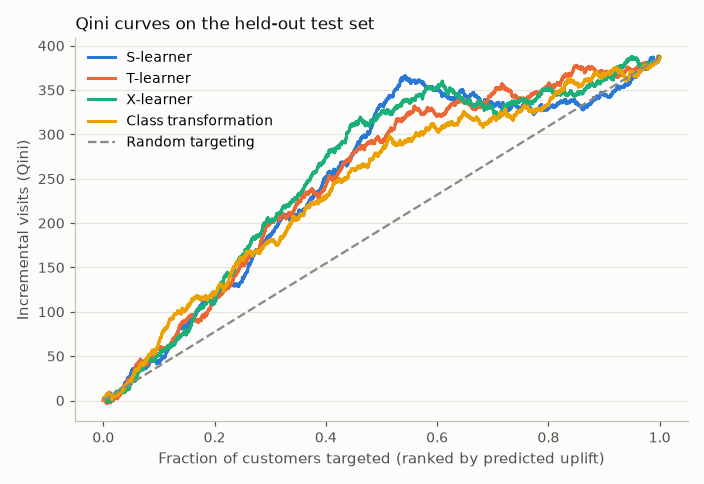

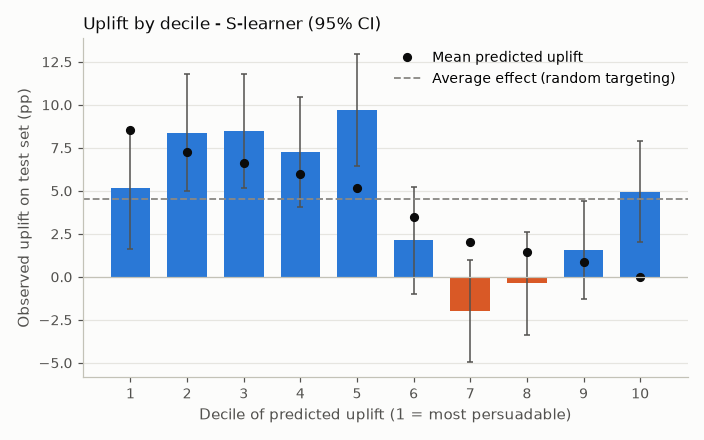

In [6]:
display(Image("../reports/figures/qini_curves.png"))
display(Image("../reports/figures/uplift_by_decile.png"))

## 4. Business simulation
Assumptions (see `CampaignEconomics`): $2.50 margin per incremental visit, $0.10 fully loaded cost per e-mail, results per 100k customers.
Break-even: a customer is worth e-mailing only if their uplift exceeds 0.10 / 2.50 = 4 percentage points.

In [7]:
pd.DataFrame(summary["business"])

,strategy,fraction,contacts,incremental_responses,campaign_cost,profit,roi
0,Contact no one,0.00,0.0,0.0000,0.0,0.0000,NaN
1,Contact everyone (blanket),1.00,100000.0,4519.0197,10000.0,1297.5493,0.1298
2,S-learner: top 54% (k chosen on CV),0.54,54000.0,4256.5724,5400.0,5241.4311,0.9706
3,Random targeting: 54%,0.54,54000.0,2490.3561,5400.0,825.8902,0.1529
4,"S-learner: best k in hindsight (test, optimistic)",0.54,54000.0,4256.5724,5400.0,5241.4311,0.9706


In [8]:
print(summary["profit_gain_vs_everyone"])
pd.DataFrame(summary["sensitivity"])

{'point': 3943.881803002805, 'ci_low': 2153.452481163145, 'ci_high': 5503.066439482066}


,cost_per_contact,break_even_uplift,chosen_k,profit_targeted,profit_everyone,gain_vs_everyone
0,0.05,0.02,0.76,6033.3273,6297.5493,-264.2219
1,0.10,0.04,0.54,5241.4311,1297.5493,3943.8818
2,0.15,0.06,0.54,2541.4311,-3702.4507,6243.8818
3,0.20,0.08,0.04,-200.8932,-8702.4507,8501.5576


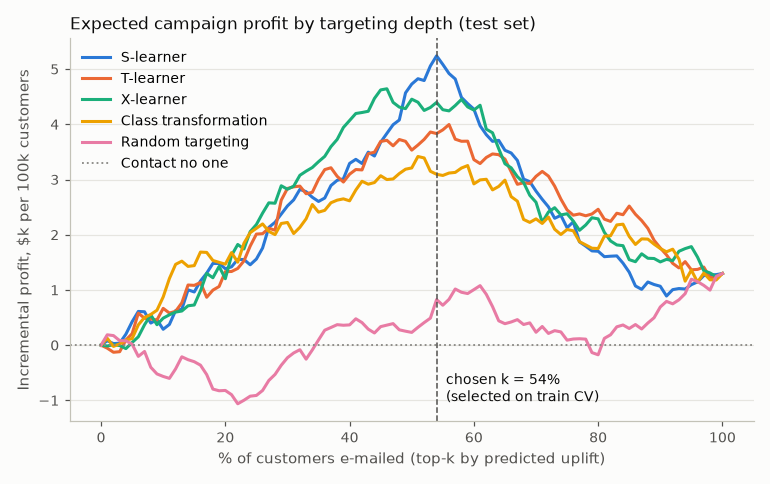

In [9]:
display(Image("../reports/figures/profit_curve.png"))

Targeting the top ~54% roughly quadruples profit vs the blanket campaign under these assumptions, with roughly half the sends.
The sensitivity table shows the logic is not a free lunch: when e-mails are very cheap ($0.05) blanket sending is marginally better,
and when they are expensive targeting is the only way to stay near break-even.

## 5. Who is persuadable?

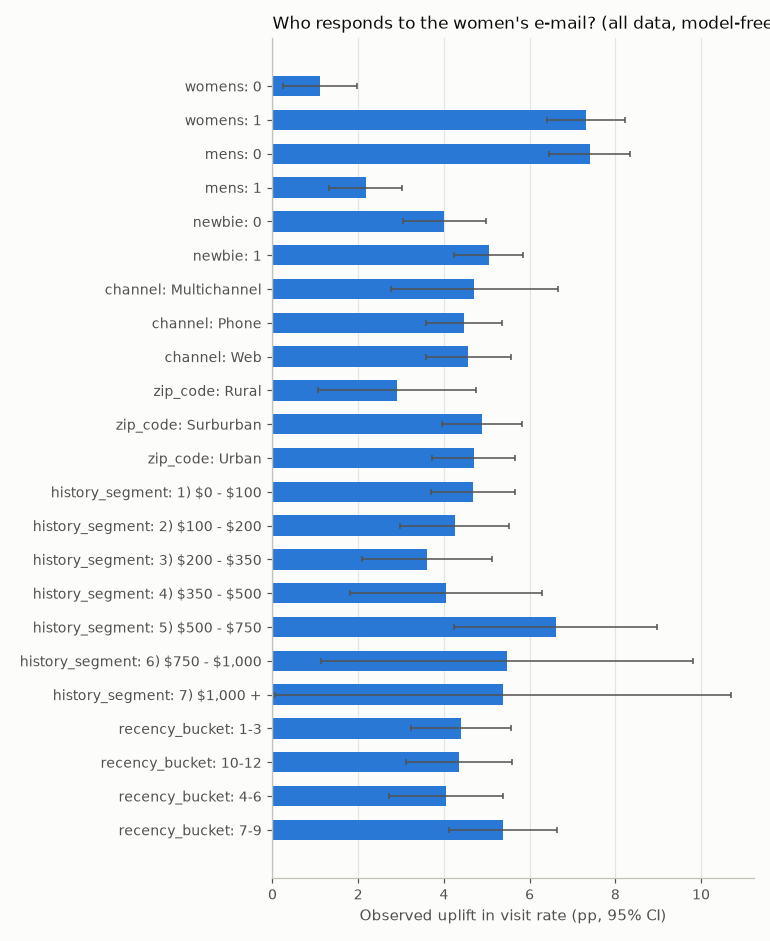

In [10]:
display(Image("../reports/figures/segment_uplift.png"))

The dominant driver is purchase history: customers who bought **women's merchandise** in the past year respond ~7 pp, others ~1 pp;
customers who bought **men's merchandise** respond much less. The detailed surrogate-tree rules and top/bottom-20% profiles are in
`reports/results.md`.

**Sleeping dogs?** Only ~3% of customers get a negative predicted uplift, and the observed uplift in the bottom 20% is still positive.
So for this e-mail the risk is wasted budget, not active harm: the low-uplift group should be skipped because they are below break-even,
not because the e-mail hurts them.

In [11]:
print("Bottom-20% observed uplift:", summary["bottom_20_observed_uplift"])
print("Share with negative predicted uplift:", summary["share_negative_predicted"])

Bottom-20% observed uplift: {'ate': np.float64(0.03255665496329396), 'ci_low': np.float64(0.012069989018458242), 'ci_high': np.float64(0.05304332090812969)}
Share with negative predicted uplift: 0.03091696920014053
